# Superstore Sales Analysis with Python

This notebook analyzes the Superstore dataset using Python.

The main steps are:
- understand and clean the data
- create new useful columns
- explore sales and profit
- check correlations and trends
- create visualizations
- generate a simple summary and export the results

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-8kpsspwx because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. Load the Dataset

In [2]:
try:
    df = pd.read_excel('Sample-Superstore-2019.xlsx')
    print('Dataset loaded successfully')
except:
    df = pd.read_excel('Sample-Superstore-2019.xls')
    print('Dataset loaded successfully')

Dataset loaded successfully


## 3. Understand the Data

In [3]:
df.shape

(9994, 21)

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   object        
 2   Order Date      9994 non-null   datetime64[ns]
 3   Ship Date       9994 non-null   datetime64[ns]
 4   Ship Mode       9994 non-null   object        
 5   Customer ID     9994 non-null   object        
 6   Customer Name   9994 non-null   object        
 7   Segment         9994 non-null   object        
 8   Country/Region  9994 non-null   object        
 9   City            9994 non-null   object        
 10  State           9994 non-null   object        
 11  Postal Code     9983 non-null   float64       
 12  Region          9994 non-null   object        
 13  Product ID      9994 non-null   object        
 14  Category        9994 non-null   object        
 15  Sub-

In [6]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [7]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2018-04-30 10:03:51.979187712,2018-05-04 09:03:29.645787392,55245.233297,229.858001,3.789574,0.156203,28.656896
min,1.000000,2016-01-03 00:00:00,2016-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2017-05-23 00:00:00,2017-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2018-06-26 00:00:00,2018-06-29 00:00:00,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2019-05-14 00:00:00,2019-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2019-12-30 00:00:00,2020-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32038.715955,623.245101,2.225110,0.206452,234.260108


In [10]:
df.nunique()

Row ID            9994
Order ID          5009
Order Date        1236
Ship Date         1334
Ship Mode            4
Customer ID        793
Customer Name      793
Segment              3
Country/Region       1
City               531
State               49
Postal Code        630
Region               4
Product ID        1862
Category             3
Sub-Category        17
Product Name      1850
Sales             5825
Quantity            14
Discount            12
Profit            7314
dtype: int64

### Check the main categorical columns

In [11]:
print(df['Ship Mode'].value_counts())
print()
print(df['Segment'].value_counts())
print()
print(df['Region'].value_counts())
print()
print(df['Category'].value_counts())
print()
print(df['Sub-Category'].value_counts())

Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64


## 4. Data Cleaning

In [12]:
# check the missing postal codes
df.loc[df['Postal Code'].isnull(), ['City', 'State', 'Region', 'Postal Code']]

,City,State,Region,Postal Code
2234,Burlington,Vermont,East,NaN
5274,Burlington,Vermont,East,NaN
8798,Burlington,Vermont,East,NaN
9146,Burlington,Vermont,East,NaN
9147,Burlington,Vermont,East,NaN
9148,Burlington,Vermont,East,NaN
9386,Burlington,Vermont,East,NaN
9387,Burlington,Vermont,East,NaN
9388,Burlington,Vermont,East,NaN
9389,Burlington,Vermont,East,NaN


In [13]:
# remove extra spaces from some text columns
text_columns = ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']

for col in text_columns:
    df[col] = df[col].str.strip()

In [14]:
# remove duplicate rows if there are any
df = df.drop_duplicates()
print('Duplicates after cleaning:', df.duplicated().sum())

Duplicates after cleaning: 0


The missing Postal Code values belong to Burlington, Vermont.  
Because the dataset does not contain a valid postal code for the same location, I keep these values as **Unknown** instead of guessing a code.

In [15]:
df['Postal Code'] = df['Postal Code'].astype('Int64')
df['Postal Code'] = df['Postal Code'].astype('string')
df['Postal Code'] = df['Postal Code'].fillna('Unknown')

print('Missing Postal Codes:', df['Postal Code'].isnull().sum())
print('Postal Code type:', df['Postal Code'].dtype)

Missing Postal Codes: 0
Postal Code type: string


### Check outliers using IQR

In [16]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_sales = Q1 - 1.5 * IQR
upper_sales = Q3 + 1.5 * IQR

sales_outliers = df[(df['Sales'] < lower_sales) | (df['Sales'] > upper_sales)]

print('Sales lower bound:', round(lower_sales, 2))
print('Sales upper bound:', round(upper_sales, 2))
print('Number of Sales outliers:', len(sales_outliers))

Sales lower bound: -271.71
Sales upper bound: 498.93
Number of Sales outliers: 1167


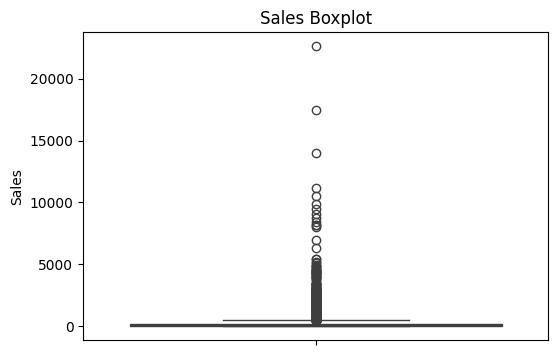

In [17]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df['Sales'])
plt.title('Sales Boxplot')
plt.show()

In [18]:
Q1_profit = df['Profit'].quantile(0.25)
Q3_profit = df['Profit'].quantile(0.75)
IQR_profit = Q3_profit - Q1_profit

lower_profit = Q1_profit - 1.5 * IQR_profit
upper_profit = Q3_profit + 1.5 * IQR_profit

profit_outliers = df[(df['Profit'] < lower_profit) | (df['Profit'] > upper_profit)]

print('Profit lower bound:', round(lower_profit, 2))
print('Profit upper bound:', round(upper_profit, 2))
print('Number of Profit outliers:', len(profit_outliers))

Profit lower bound: -39.72
Profit upper bound: 70.82
Number of Profit outliers: 1881


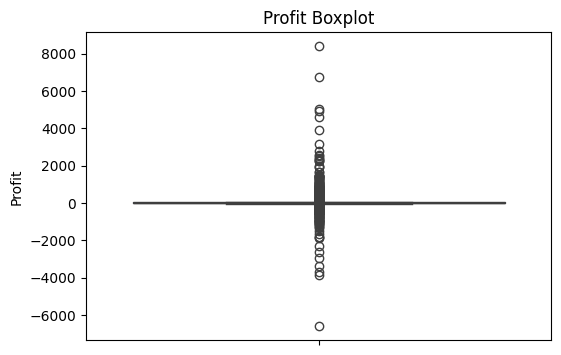

In [19]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df['Profit'])
plt.title('Profit Boxplot')
plt.show()

The outliers were checked but not removed because the largest values look like real high-value sales and real large profits/losses, not data entry errors.

### Check basic logical values

In [20]:
print('Sales equal to zero:', (df['Sales'] == 0).sum())
print('Quantity less than or equal to zero:', (df['Quantity'] <= 0).sum())
print('Discount less than 0:', (df['Discount'] < 0).sum())
print('Discount greater than 1:', (df['Discount'] > 1).sum())
print('Ship date before order date:', (df['Ship Date'] < df['Order Date']).sum())

Sales equal to zero: 0
Quantity less than or equal to zero: 0
Discount less than 0: 0
Discount greater than 1: 0
Ship date before order date: 0


## 5. Feature Engineering

In [21]:
df['Ship Duration'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Profit Margin'] = (df['Profit'] / df['Sales']) * 100

Q33 = df['Sales'].quantile(0.33)
Q66 = df['Sales'].quantile(0.66)

df['Sales Performance Category'] = np.where(
    df['Sales'] <= Q33,
    'Low',
    np.where(df['Sales'] <= Q66, 'Medium', 'High')
)

df[['Sales', 'Profit', 'Ship Duration', 'Profit Margin', 'Sales Performance Category']].head()

,Sales,Profit,Ship Duration,Profit Margin,Sales Performance Category
0,261.9600,41.9136,3,16.00,High
1,731.9400,219.5820,3,30.00,High
2,14.6200,6.8714,4,47.00,Low
3,957.5775,-383.0310,7,-40.00,High
4,22.3680,2.5164,7,11.25,Low


In [22]:
df['Sales Performance Category'].value_counts()

Sales Performance Category
High      3398
Low       3298
Medium    3298
Name: count, dtype: int64

## 6. Reusable Preprocessing Function

In [23]:
def preprocess_data(data):
    data = data.copy()

    data = data.drop_duplicates()

    data['Postal Code'] = data['Postal Code'].astype('Int64')
    data['Postal Code'] = data['Postal Code'].astype('string')
    data['Postal Code'] = data['Postal Code'].fillna('Unknown')

    data['Ship Duration'] = (data['Ship Date'] - data['Order Date']).dt.days
    data['Profit Margin'] = (data['Profit'] / data['Sales']) * 100

    q33 = data['Sales'].quantile(0.33)
    q66 = data['Sales'].quantile(0.66)

    data['Sales Performance Category'] = np.where(
        data['Sales'] <= q33,
        'Low',
        np.where(data['Sales'] <= q66, 'Medium', 'High')
    )

    return data

In [24]:
# simple test of the function using the original file
test_df = pd.read_excel('Sample-Superstore-2019.xlsx')
test_df = preprocess_data(test_df)

test_df[['Postal Code', 'Ship Duration', 'Profit Margin', 'Sales Performance Category']].head()

,Postal Code,Ship Duration,Profit Margin,Sales Performance Category
0,42420,3,16.00,High
1,42420,3,30.00,High
2,90036,4,47.00,Low
3,33311,7,-40.00,High
4,33311,7,11.25,Low


## 7. Exploratory Data Analysis

### Sales and Profit by Category

In [25]:
category_sales = df.groupby('Category', as_index=False)['Sales'].sum()
category_sales = category_sales.sort_values('Sales', ascending=False)
category_sales

,Category,Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320


In [26]:
category_profit = df.groupby('Category', as_index=False)['Profit'].sum()
category_profit = category_profit.sort_values('Profit', ascending=False)
category_profit

,Category,Profit
2,Technology,145454.9481
1,Office Supplies,122490.8008
0,Furniture,18451.2728


### Top and Bottom Sub-Categories

In [27]:
sub_category = df.groupby('Sub-Category', as_index=False)[['Sales', 'Profit']].sum()

print('Top 5 by Sales')
display(sub_category.sort_values('Sales', ascending=False).head())

print('Top 5 by Profit')
display(sub_category.sort_values('Profit', ascending=False).head())

print('Bottom 5 by Profit')
display(sub_category.sort_values('Profit', ascending=True).head())

Top 5 by Sales


,Sub-Category,Sales,Profit
13,Phones,330007.054,44515.7306
5,Chairs,328449.103,26590.1663
14,Storage,223843.608,21278.8264
16,Tables,206965.532,-17725.4811
3,Binders,203412.733,30221.7633


Top 5 by Profit


,Sub-Category,Sales,Profit
6,Copiers,149528.030,55617.8249
13,Phones,330007.054,44515.7306
0,Accessories,167380.318,41936.6357
12,Paper,78479.206,34053.5693
3,Binders,203412.733,30221.7633


Bottom 5 by Profit


,Sub-Category,Sales,Profit
16,Tables,206965.5320,-17725.4811
4,Bookcases,114879.9963,-3472.5560
15,Supplies,46673.5380,-1189.0995
8,Fasteners,3024.2800,949.5182
11,Machines,189238.6310,3384.7569


### Discount and Profit

In [28]:
discount_profit = df.groupby('Discount', as_index=False)['Profit'].sum()
discount_profit

,Discount,Profit
0,0.00,320987.6032
1,0.10,9029.1770
2,0.15,1418.9915
3,0.20,90337.3060
4,0.30,-10369.2774
5,0.32,-2391.1377
6,0.40,-23057.0504
7,0.45,-2493.1111
8,0.50,-20506.4281
9,0.60,-5944.6552


### Region and Segment

In [29]:
region_sales = df.groupby('Region', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
segment_sales = df.groupby('Segment', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)

display(region_sales)
display(segment_sales)

,Region,Sales
3,West,725457.8245
1,East,678781.2400
0,Central,501239.8908
2,South,391721.9050


,Segment,Sales
0,Consumer,1.161401e+06
1,Corporate,7.061464e+05
2,Home Office,4.296531e+05


## 8. Statistical Analysis

### Correlation

In [30]:
numeric_columns = ['Sales', 'Quantity', 'Discount', 'Profit', 'Ship Duration', 'Profit Margin']
correlation = df[numeric_columns].corr()
correlation.round(2)

,Sales,Quantity,Discount,Profit,Ship Duration,Profit Margin
Sales,1.00,0.20,-0.03,0.48,-0.01,0.00
Quantity,0.20,1.00,0.01,0.07,0.02,-0.01
Discount,-0.03,0.01,1.00,-0.22,0.00,-0.86
Profit,0.48,0.07,-0.22,1.00,-0.00,0.22
Ship Duration,-0.01,0.02,0.00,-0.00,1.00,-0.01
Profit Margin,0.00,-0.01,-0.86,0.22,-0.01,1.00


### Monthly Sales Trend

In [31]:
df['Order Month'] = df['Order Date'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Order Month', as_index=False)['Sales'].sum()
monthly_sales.head()

,Order Month,Sales
0,2016-01,14236.895
1,2016-02,4519.892
2,2016-03,55691.009
3,2016-04,28295.345
4,2016-05,23648.287


## 9. Visualizations

In [32]:
os.makedirs('charts', exist_ok=True)

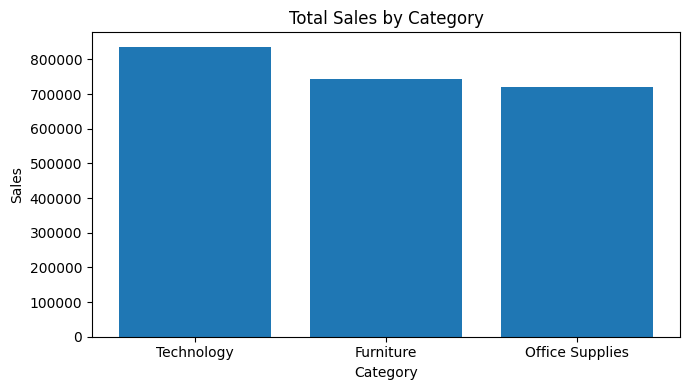

In [33]:
plt.figure(figsize=(7,4))
plt.bar(category_sales['Category'], category_sales['Sales'])
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.tight_layout()
plt.savefig('charts/1_sales_by_category.png')
plt.show()

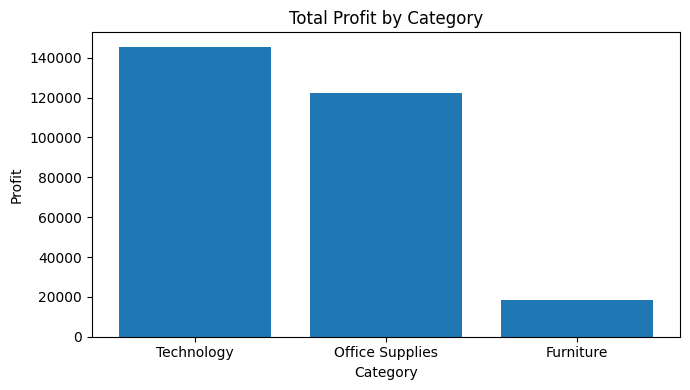

In [34]:
plt.figure(figsize=(7,4))
plt.bar(category_profit['Category'], category_profit['Profit'])
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Profit')
plt.tight_layout()
plt.savefig('charts/2_profit_by_category.png')
plt.show()

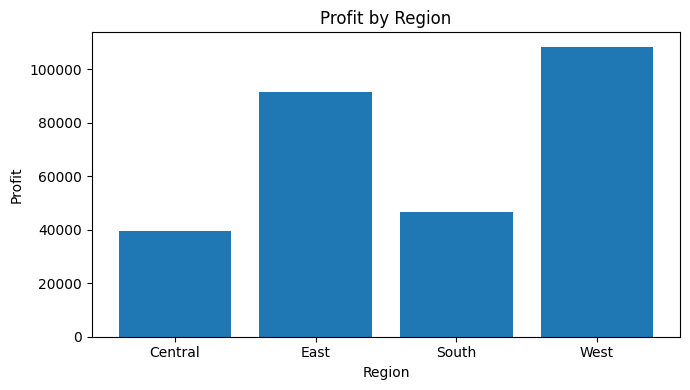

In [35]:
region_profit = df.groupby('Region', as_index=False)['Profit'].sum()

plt.figure(figsize=(7,4))
plt.bar(region_profit['Region'], region_profit['Profit'])
plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Profit')
plt.tight_layout()
plt.savefig('charts/3_profit_by_region.png')
plt.show()

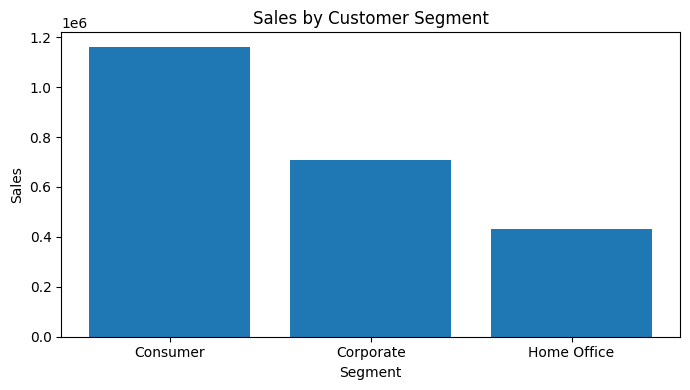

In [36]:
plt.figure(figsize=(7,4))
plt.bar(segment_sales['Segment'], segment_sales['Sales'])
plt.title('Sales by Customer Segment')
plt.xlabel('Segment')
plt.ylabel('Sales')
plt.tight_layout()
plt.savefig('charts/4_sales_by_segment.png')
plt.show()

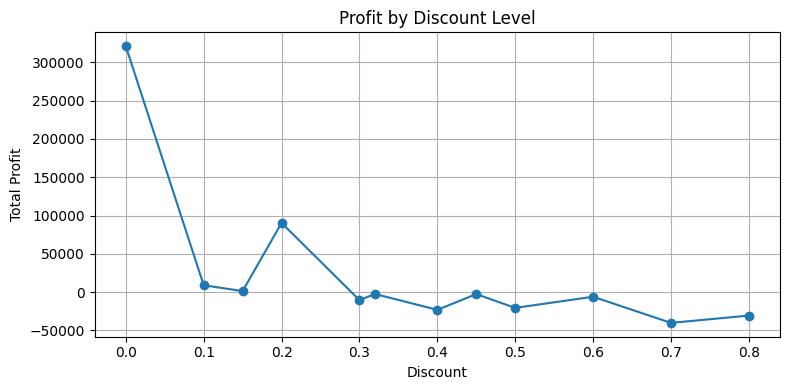

In [37]:
plt.figure(figsize=(8,4))
plt.plot(discount_profit['Discount'], discount_profit['Profit'], marker='o')
plt.title('Profit by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Total Profit')
plt.grid(True)
plt.tight_layout()
plt.savefig('charts/5_profit_by_discount.png')
plt.show()

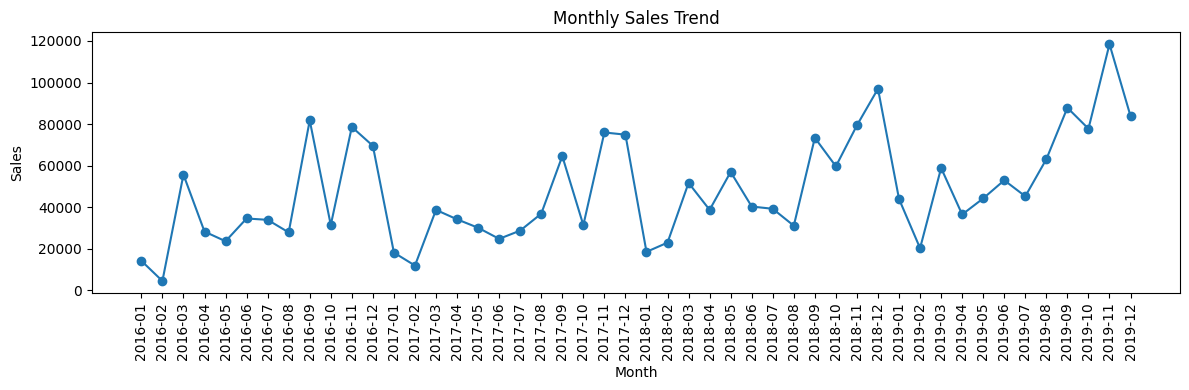

In [38]:
plt.figure(figsize=(12,4))
plt.plot(monthly_sales['Order Month'], monthly_sales['Sales'], marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('charts/6_monthly_sales_trend.png')
plt.show()

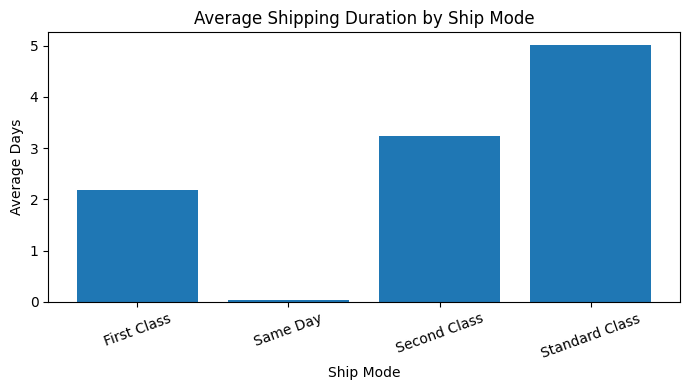

In [39]:
ship_mode_duration = df.groupby('Ship Mode', as_index=False)['Ship Duration'].mean()

plt.figure(figsize=(7,4))
plt.bar(ship_mode_duration['Ship Mode'], ship_mode_duration['Ship Duration'])
plt.title('Average Shipping Duration by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Average Days')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('charts/7_shipping_duration.png')
plt.show()

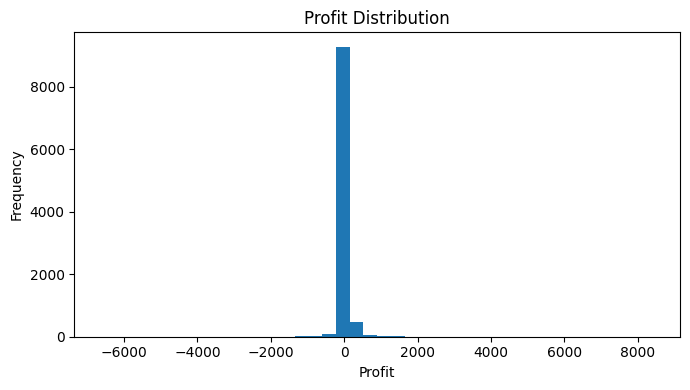

In [40]:
plt.figure(figsize=(7,4))
plt.hist(df['Profit'], bins=40)
plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('charts/8_profit_distribution.png')
plt.show()

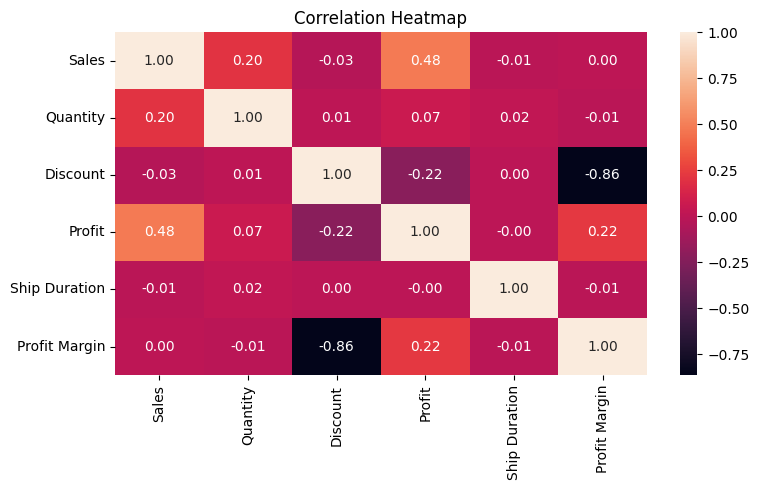

In [41]:
plt.figure(figsize=(8,5))
sns.heatmap(correlation, annot=True, fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('charts/9_correlation_heatmap.png')
plt.show()

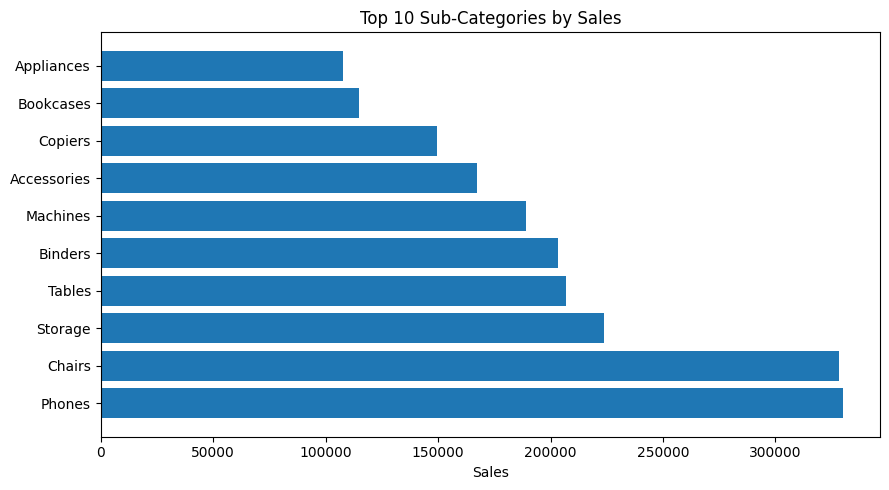

In [42]:
top_sub_sales = sub_category.sort_values('Sales', ascending=False).head(10)

plt.figure(figsize=(9,5))
plt.barh(top_sub_sales['Sub-Category'], top_sub_sales['Sales'])
plt.title('Top 10 Sub-Categories by Sales')
plt.xlabel('Sales')
plt.tight_layout()
plt.savefig('charts/10_top_subcategories.png')
plt.show()

## 10. KPI Summary

In [43]:
def show_summary(data):
    print('Total Sales:', round(data['Sales'].sum(), 2))
    print('Total Profit:', round(data['Profit'].sum(), 2))
    print('Number of Orders:', data['Order ID'].nunique())
    print('Number of Customers:', data['Customer ID'].nunique())
    print('Average Order Sales:', round(data['Sales'].mean(), 2))
    print('Average Shipping Duration:', round(data['Ship Duration'].mean(), 2), 'days')

show_summary(df)

Total Sales: 2297200.86
Total Profit: 286397.02
Number of Orders: 5009
Number of Customers: 793
Average Order Sales: 229.86
Average Shipping Duration: 3.96 days


## 11. Simple OOP Example

In [44]:
class StoreReport:

    def __init__(self, data):
        self.data = data

    def total_sales(self):
        return self.data['Sales'].sum()

    def total_profit(self):
        return self.data['Profit'].sum()

    def show(self):
        print('Total Sales:', round(self.total_sales(), 2))
        print('Total Profit:', round(self.total_profit(), 2))

report = StoreReport(df)
report.show()

Total Sales: 2297200.86
Total Profit: 286397.02


## 12. Memory Usage

In [45]:
memory_before = df.memory_usage(deep=True).sum() / 1024**2

optimized_df = df.copy()

category_columns = ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category', 'Sales Performance Category']

for col in category_columns:
    optimized_df[col] = optimized_df[col].astype('category')

memory_after = optimized_df.memory_usage(deep=True).sum() / 1024**2

print('Memory before:', round(memory_before, 2), 'MB')
print('Memory after:', round(memory_after, 2), 'MB')

Memory before: 9.9 MB
Memory after: 6.68 MB


## 13. Export Results

In [46]:
df.to_csv('cleaned_superstore.csv', index=False)

with open('summary_report.txt', 'w') as file:
    file.write('Superstore Analysis Summary\n')
    file.write('Total Sales: ' + str(round(df['Sales'].sum(), 2)) + '\n')
    file.write('Total Profit: ' + str(round(df['Profit'].sum(), 2)) + '\n')
    file.write('Number of Orders: ' + str(df['Order ID'].nunique()) + '\n')
    file.write('Number of Customers: ' + str(df['Customer ID'].nunique()) + '\n')
    file.write('Average Shipping Duration: ' + str(round(df['Ship Duration'].mean(), 2)) + ' days\n')

print('Files exported successfully')

Files exported successfully


## 14. Main Findings

- Technology has the highest total sales and profit.
- Furniture has high sales but lower profit compared with the other categories.
- Tables is one of the main loss-making sub-categories.
- Large discounts are often connected with lower profit and losses.
- The sales and profit outliers were kept because they appear to be real business transactions.
- Shipping duration changes depending on the selected ship mode.